# Final models

Here I try two ensembles, a random forest and gradient boosting, and compare them with everything from notebooks 03 and 04. Then I pick my final model and a threshold for it. Like before, I only use the training set with the same 5 folds. The test set stays untouched.

In [1]:
# Add the project folder to the path so `from src import ...` works when this
# notebook is run from the notebooks folder.
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_predict

from src.baselines import SCORING
from src.clean import clean
from src.evaluation import make_cv, split_by_lifter
from src.features import FEATURES, build_features
from src.models import (GB_GRID, RF_GRID, make_decision_tree, make_gradient_boosting,
                        make_logistic_regression, make_random_forest, tune)
from src.paths import INTERIM, REPORTS

cohort = pd.read_csv(INTERIM / 'audit_cohort.csv.gz', dtype=str, keep_default_na=False)
cleaned, _ = clean(cohort)
table = build_features(cleaned)

# I only keep the training side. The test set isn't used anywhere in this notebook.
train, _ = split_by_lifter(table)
X_train, y_train, groups_train = train[FEATURES], train['made'], train['Name']
print('training rows:', len(X_train))

training rows: 369880


## 1. Ensembles

In [2]:
start = time.perf_counter()
rf_search = tune(make_random_forest(), RF_GRID, X_train, y_train, groups_train)
print(f'random forest took {time.perf_counter() - start:.0f} seconds')
print('best settings:', rf_search.best_params_)

# Mean and std of balanced accuracy across the 5 folds for each setting I tried.
rf_table = pd.DataFrame({
    'max_depth': rf_search.cv_results_['param_model__max_depth'],
    'min_samples_leaf': rf_search.cv_results_['param_model__min_samples_leaf'],
    'balanced_accuracy_mean': rf_search.cv_results_['mean_test_balanced_accuracy'],
    'balanced_accuracy_std': rf_search.cv_results_['std_test_balanced_accuracy'],
}).round(4)
rf_table

random forest took 243 seconds
best settings: {'model__max_depth': 15, 'model__min_samples_leaf': 50}


,max_depth,min_samples_leaf,balanced_accuracy_mean,balanced_accuracy_std
0,10,50,0.6205,0.0017
1,10,200,0.6201,0.0020
2,15,50,0.6206,0.0016
3,15,200,0.6206,0.0017


In [3]:
start = time.perf_counter()
gb_search = tune(make_gradient_boosting(), GB_GRID, X_train, y_train, groups_train)
print(f'gradient boosting took {time.perf_counter() - start:.0f} seconds')
print('best settings:', gb_search.best_params_)

gb_table = pd.DataFrame({
    'learning_rate': gb_search.cv_results_['param_model__learning_rate'],
    'max_leaf_nodes': gb_search.cv_results_['param_model__max_leaf_nodes'],
    'min_samples_leaf': gb_search.cv_results_['param_model__min_samples_leaf'],
    'balanced_accuracy_mean': gb_search.cv_results_['mean_test_balanced_accuracy'],
    'balanced_accuracy_std': gb_search.cv_results_['std_test_balanced_accuracy'],
}).round(4)
gb_table

gradient boosting took 127 seconds
best settings: {'model__learning_rate': 0.05, 'model__max_leaf_nodes': 31, 'model__min_samples_leaf': 200}


,learning_rate,max_leaf_nodes,min_samples_leaf,balanced_accuracy_mean,balanced_accuracy_std
0,0.05,31,50,0.6212,0.0012
1,0.05,31,200,0.6216,0.0011
2,0.05,63,50,0.6214,0.0016
3,0.05,63,200,0.6214,0.0014
4,0.10,31,50,0.6214,0.0011
5,0.10,31,200,0.6211,0.0014
6,0.10,63,50,0.6209,0.0015
7,0.10,63,200,0.6213,0.0014


## What the ensembles found

The random forest took 243 seconds to tune and gradient boosting took 127 seconds, so the forest took about twice as long even though it had 4 settings to try and gradient boosting had 8. For the forest, the best setting was a max depth of 15 with a minimum leaf size of 50, at 0.6206 balanced accuracy, and all four settings landed between 0.6201 and 0.6206. For gradient boosting, the best was a learning rate of 0.05, 31 leaves per tree and a minimum leaf size of 200, at 0.6216, and all eight settings landed between 0.6209 and 0.6216. So like with logistic regression in notebook 04, the settings I tried made very little difference. The gaps between settings are all smaller than the fold std (0.0011 to 0.0020).

## 2. All models compared

In [4]:
def best_row(search):
    """The fold scores for the setting each search picked, with the same column names
    as model_results.csv."""
    i = search.best_index_
    row = {}
    for metric in SCORING:
        row[f'{metric}_mean'] = search.cv_results_[f'mean_test_{metric}'][i]
        row[f'{metric}_std'] = search.cv_results_[f'std_test_{metric}'][i]
    return row

# The baselines, logistic regression and the tree come from notebook 04.
model_results = pd.read_csv(REPORTS / 'model_results.csv', index_col=0)
ensembles = pd.DataFrame({'random forest': best_row(rf_search),
                          'gradient boosting': best_row(gb_search)}).T
final_results = pd.concat([model_results, ensembles])[model_results.columns].round(4)
final_results.index.name = 'model'
final_results.to_csv(REPORTS / 'final_cv_results.csv')

# The scores I care about most go first.
first = [f'{m}_{s}' for m in ['balanced_accuracy', 'roc_auc', 'accuracy', 'recall_missed']
         for s in ['mean', 'std']]
final_results[first + [c for c in final_results.columns if c not in first]]

,balanced_accuracy_mean,balanced_accuracy_std,roc_auc_mean,roc_auc_std,accuracy_mean,accuracy_std,recall_missed_mean,recall_missed_std,precision_made_mean,precision_made_std,recall_made_mean,recall_made_std,f1_made_mean,f1_made_std,precision_missed_mean,precision_missed_std,f1_missed_mean,f1_missed_std
model,,,,,,,,,,,,,,,,,,
always made,0.5000,0.0000,0.5000,0.0000,0.6102,0.0000,0.0000,0.0000,0.6102,0.0000,1.0000,0.0000,0.7579,0.0000,0.0000,0.0000,0.0000,0.0000
second-attempt rule,0.5553,0.0010,0.5553,0.0010,0.6383,0.0008,0.1792,0.0022,0.6399,0.0006,0.9315,0.0008,0.7586,0.0004,0.6256,0.0030,0.2785,0.0029
logistic regression,0.6113,0.0015,0.6562,0.0019,0.6209,0.0016,0.5680,0.0029,0.7035,0.0013,0.6546,0.0026,0.6782,0.0016,0.5123,0.0018,0.5387,0.0019
decision tree,0.6174,0.0016,0.6629,0.0022,0.6213,0.0036,0.6000,0.0122,0.7131,0.0024,0.6349,0.0132,0.6716,0.0066,0.5122,0.0042,0.5525,0.0033
random forest,0.6206,0.0016,0.6693,0.0019,0.6246,0.0017,0.6023,0.0023,0.7155,0.0013,0.6389,0.0027,0.6750,0.0019,0.5158,0.0019,0.5557,0.0017
gradient boosting,0.6216,0.0011,0.6701,0.0020,0.6249,0.0017,0.6068,0.0024,0.7170,0.0007,0.6364,0.0039,0.6743,0.0023,0.5160,0.0019,0.5577,0.0009


## 3. Choosing the final model

In [5]:
ranked = final_results.sort_values('balanced_accuracy_mean', ascending=False)
best_name, next_name = ranked.index[:2]
best, runner_up = ranked.loc[best_name], ranked.loc[next_name]
gap = best.balanced_accuracy_mean - runner_up.balanced_accuracy_mean
print('best model:', best_name, round(best.balanced_accuracy_mean, 4),
      'std', round(best.balanced_accuracy_std, 4))
print('next model:', next_name, round(runner_up.balanced_accuracy_mean, 4),
      'std', round(runner_up.balanced_accuracy_std, 4))
print('gap:', round(gap, 4))
print('gap bigger than both fold stds:',
      gap > max(best.balanced_accuracy_std, runner_up.balanced_accuracy_std))

best model: gradient boosting 0.6216 std 0.0011
next model: random forest 0.6206 std 0.0016
gap: 0.001
gap bigger than both fold stds: False


## Which model I picked

Gradient boosting has the highest mean balanced accuracy, 0.6216 (std 0.0011), so it's my final model. But the random forest is only 0.0010 behind at 0.6206 (std 0.0016), and that gap is smaller than the fold std of either model. So I can't honestly say gradient boosting is better than the forest. On these folds they do about the same. Gradient boosting is also a little ahead on ROC-AUC (0.6701 against 0.6693) and recall on misses (0.6068 against 0.6023), but those gaps are small too.

Neither ensemble is easy to explain, because both are made of many trees. The forest is a bit simpler: it's the average of 100 trees grown separately, while in gradient boosting each tree depends on the ones before it. The simplest model of all is still the single decision tree from notebook 04, which is 0.0042 behind gradient boosting at 0.6174. That gap is bigger than the fold std of either model, so the ensembles are a real but small step up from the tree. I'm keeping gradient boosting because my rule was to pick the highest mean.

## 4. Choosing a threshold

In [6]:
# A fresh copy of each model with the settings its search picked. Logistic regression and
# the tree use the settings notebook 04 picked.
final_models = {'logistic regression': make_logistic_regression(C=10),
                'decision tree': make_decision_tree(max_depth=8, min_samples_leaf=50),
                'random forest': rf_search.best_estimator_,
                'gradient boosting': gb_search.best_estimator_}

# Every training row is predicted by a copy of the model fitted on the other 4 folds,
# so the lifter in that row was never seen in training.
start = time.perf_counter()
oof_prob = cross_val_predict(final_models[best_name], X_train, y_train, groups=groups_train,
                             cv=make_cv(), method='predict_proba', n_jobs=-1)[:, 1]
print(f'out-of-fold probabilities took {time.perf_counter() - start:.0f} seconds')

# A lift is called made if its probability is at least the threshold.
made, missed = y_train.to_numpy() == 1, y_train.to_numpy() == 0
rows = []
for threshold in np.round(np.arange(0.30, 0.701, 0.01), 2):
    predicted_made = oof_prob >= threshold
    recall_made = predicted_made[made].mean()
    recall_missed = (~predicted_made)[missed].mean()
    rows.append({'threshold': threshold, 'balanced_accuracy': (recall_made + recall_missed) / 2,
                 'recall_missed': recall_missed, 'recall_made': recall_made})
thresholds = pd.DataFrame(rows).set_index('threshold')

best_threshold = thresholds.balanced_accuracy.idxmax()
print('best threshold:', best_threshold)
print('balanced accuracy at 0.5:', round(thresholds.balanced_accuracy[0.5], 4))
print('balanced accuracy at the best threshold:',
      round(thresholds.balanced_accuracy[best_threshold], 4))
# The thresholds just around the best one.
thresholds.loc[best_threshold - 0.05:best_threshold + 0.05].round(4)

out-of-fold probabilities took 54 seconds


best threshold: 0.5
balanced accuracy at 0.5: 0.6216
balanced accuracy at the best threshold: 0.6216


,balanced_accuracy,recall_missed,recall_made
threshold,,,
0.45,0.6145,0.4705,0.7584
0.46,0.6168,0.4985,0.7352
0.47,0.6187,0.5249,0.7126
0.48,0.6201,0.5520,0.6882
0.49,0.6208,0.5788,0.6629
0.50,0.6216,0.6068,0.6364
0.51,0.6212,0.6324,0.6099
0.52,0.6206,0.6583,0.5829
0.53,0.6189,0.6820,0.5559


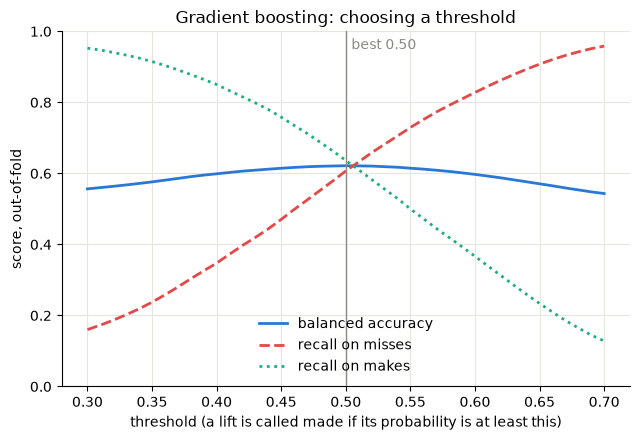

In [7]:
FIGURES = REPORTS / 'figures'
FIGURES.mkdir(exist_ok=True)

# The same colours and look as the figures in notebook 04.
BLUE, ORANGE, AQUA, RED, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#e34948', '#8a8a85'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True})

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(thresholds.index, thresholds.balanced_accuracy, color=BLUE, linewidth=2,
        label='balanced accuracy')
ax.plot(thresholds.index, thresholds.recall_missed, color=RED, linestyle='--', linewidth=2,
        label='recall on misses')
ax.plot(thresholds.index, thresholds.recall_made, color=AQUA, linestyle=':', linewidth=2,
        label='recall on makes')
ax.axvline(best_threshold, color=GREY, linewidth=1)
ax.annotate(f'best {best_threshold:.2f}', (best_threshold, 0.95), xytext=(4, 0),
            textcoords='offset points', color=GREY)
ax.set_ylim(0, 1)
ax.set_xlabel('threshold (a lift is called made if its probability is at least this)')
ax.set_ylabel('score, out-of-fold')
ax.set_title(f'{best_name.capitalize()}: choosing a threshold')
ax.legend(loc='lower center', frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / 'threshold.png', dpi=150)
plt.show()

## The threshold trade-off

The model gives every lift a probability of being made, and the threshold is the cut-off. A lift is called made if its probability is at least the threshold, so a higher threshold calls more lifts a miss. That catches more of the real misses but wrongly flags more of the makes. Going from 0.45 to 0.55, recall on misses goes up from 0.4705 to 0.7293, and recall on makes drops from 0.7584 to 0.5000.

The best out-of-fold balanced accuracy was at 0.50, the default, with 0.6216. So moving the threshold gained nothing here. I expected any gain to be small, because class_weight='balanced' already makes each missed lift count for more during training, which pushes the best threshold close to 0.5. The curve is also flat near the top: everything from 0.48 to 0.52 is within 0.0015 of the best. I'll keep 0.50 for my final model.